In [1]:

# STEP 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# STEP 2: Upload our project CSV files

from google.colab import files
uploaded = files.upload()


Saving candidates.csv to candidates.csv
Saving comments.csv to comments.csv
Saving evidence.csv to evidence.csv
Saving posts.csv to posts.csv
Saving recommendations.csv to recommendations.csv


In [3]:

# STEP 3: Load CSV datasets

posts = pd.read_csv("posts.csv")
comments = pd.read_csv("comments.csv")

print("===== DATASET OVERVIEW =====")
print("Total Posts:", posts.shape[0])
print("Total Comments:", comments.shape[0])

print("\n===== POSTS DATASET =====")
display(posts.head())

print("\n===== COMMENTS DATASET =====")
display(comments.head())

print("\n===== POSTS COLUMNS =====")
print(posts.columns.tolist())

print("\n===== COMMENTS COLUMNS =====")
print(comments.columns.tolist())

print("\n===== MISSING VALUES =====")
print("Posts:")
display(posts.isnull().sum().to_frame("Missing Values"))

print("Comments:")
display(comments.isnull().sum().to_frame("Missing Values"))


===== DATASET OVERVIEW =====
Total Posts: 159
Total Comments: 2118

===== POSTS DATASET =====


,post_id,brand,platform,post_date,post_time,post_type,likes,comments_count,views_reported,views_approximate,...,followers_at_collection,caption,content_category,content_tags,hashtags,collection_date,data_source,notes,data_quality_flags,needs_review
0,KH_IG_001,Khaadi,Instagram,2026-10-15,NaN,Reel,532.0,15.0,104000.0,yes,...,NaN,"khaddi, New Arrivals, Wear Yourself",New Arrivals,New Arrivals; Wear Yourself,NaN,2026-10-16,user-provided,104k reported; rounded; brand caption spelling...,NaN,no
1,KH_IG_002,Khaadi,Instagram,2026-10-12,NaN,Reel,493.0,4.0,111000.0,yes,...,NaN,"Khaadi, New Arrivals, Ready To Wear, Wear Your...",New Arrivals,New Arrivals; Ready To Wear; Wear Yourself,NaN,2026-10-16,user-provided,111k reported; rounded,NaN,no
2,KH_IG_003,Khaadi,Instagram,2026-10-11,NaN,Image,1740.0,23.0,NaN,NaN,...,NaN,khaadi Who says basics have to be boring? Thin...,Basics / Solids,New Arrivals; Solids; Basics; Ready To Wear; W...,NaN,2026-10-16,user-provided,NaN,NaN,no
3,KH_IG_004,Khaadi,Instagram,2026-10-10,NaN,Image,1038.0,18.0,NaN,NaN,...,NaN,"khaadi Snap. Button. Out the door (Khaadi, New...",Winter / Co-ords,New Arrivals; Winter; Co-ords; Wear Yourself,NaN,2026-10-16,user-provided,NaN,NaN,no
4,KH_IG_005,Khaadi,Instagram,2026-10-12,NaN,Carousel,580.0,8.0,NaN,NaN,...,NaN,"khaadi Soft hues, statement florals that bloom...",Florals / Ready To Wear,Ready To Wear; Wear Yourself; New Arrivals,NaN,2026-10-16,user-provided,Carousel (1/19 visible in screenshot); 3 of 8 ...,NaN,no



===== COMMENTS DATASET =====


,comment_id,post_id,platform,post_type,comment_text,manual_sentiment,language,topic,source,is_reply,language_standardized,normalized_text,data_quality_flags,needs_review,intent_rule_label,sentiment_model_prediction,sentiment_prediction_confidence,label_status,recommended_manual_review
0,KH_IG_001_C001,KH_IG_001,Instagram,Reel,😍😍,Positive,emoji_only,product_praise,user_provided_screenshot,unknown,Emoji_only,😍😍,NaN,no,Appreciation,Positive,0.858,Provisional_existing,no
1,KH_IG_001_C002,KH_IG_001,Instagram,Reel,Beautiful!!!,Positive,en,product_praise,user_provided_screenshot,unknown,English_or_mixed,beautiful!!!,NaN,no,Appreciation,Positive,0.841,Provisional_existing,no
2,KH_IG_001_C003,KH_IG_001,Instagram,Reel,Nice,Positive,en,product_praise,user_provided_screenshot,unknown,English_or_mixed,nice,NaN,no,Appreciation,Positive,0.562,Provisional_existing,yes
3,KH_IG_001_C004,KH_IG_001,Instagram,Reel,Worst experience,Negative,en,customer_experience,user_provided_screenshot,unknown,English_or_mixed,worst experience,NaN,no,Other_or_unclear,Positive,0.498,Provisional_existing,yes
4,KH_IG_001_C005,KH_IG_001,Instagram,Reel,They sent me torn dupatta,Negative,en,product_quality,user_provided_screenshot,unknown,English_or_mixed,they sent me torn dupatta,NaN,no,Other_or_unclear,Positive,0.450,Provisional_existing,yes



===== POSTS COLUMNS =====
['post_id', 'brand', 'platform', 'post_date', 'post_time', 'post_type', 'likes', 'comments_count', 'views_reported', 'views_approximate', 'shares', 'saves', 'followers_at_collection', 'caption', 'content_category', 'content_tags', 'hashtags', 'collection_date', 'data_source', 'notes', 'data_quality_flags', 'needs_review']

===== COMMENTS COLUMNS =====
['comment_id', 'post_id', 'platform', 'post_type', 'comment_text', 'manual_sentiment', 'language', 'topic', 'source', 'is_reply', 'language_standardized', 'normalized_text', 'data_quality_flags', 'needs_review', 'intent_rule_label', 'sentiment_model_prediction', 'sentiment_prediction_confidence', 'label_status', 'recommended_manual_review']

===== MISSING VALUES =====
Posts:


,Missing Values
post_id,0
brand,0
platform,0
post_date,4
post_time,27
post_type,0
likes,6
comments_count,3
views_reported,133
views_approximate,140


Comments:


,Missing Values
comment_id,0
post_id,0
platform,0
post_type,0
comment_text,0
manual_sentiment,0
language,0
topic,0
source,0
is_reply,0


In [4]:

# STEP 4: Data Cleaning & Preprocessing

import re
import pandas as pd
import numpy as np

# 1. Make copies to preserve original datasets
posts_clean = posts.copy()
comments_clean = comments.copy()

# 2. Standardize missing values
missing_values = ["NA", "N/A", "null", "None", "", "nan"]

posts_clean = posts_clean.replace(missing_values, np.nan)
comments_clean = comments_clean.replace(missing_values, np.nan)

# 3. Remove duplicate IDs (not repeated comment text)
posts_before = len(posts_clean)
comments_before = len(comments_clean)

posts_clean = posts_clean.drop_duplicates(
    subset=["post_id"], keep="first"
)

comments_clean = comments_clean.drop_duplicates(
    subset=["comment_id"], keep="first"
)

# 4. Remove comments with no usable text
comments_clean = comments_clean.dropna(
    subset=["comment_text", "post_id"]
).copy()

# 5. Standardize text while preserving Urdu
def clean_text(text):
    text = str(text)
    text = re.sub(r"https?://\S+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

comments_clean["clean_text"] = (
    comments_clean["comment_text"].apply(clean_text)
)

comments_clean = comments_clean[
    comments_clean["clean_text"].str.len() > 0
].copy()

# 6. Convert engagement metrics to numeric values
numeric_cols = [
    "likes", "comments_count", "views_reported",
    "shares", "saves"
]

for col in numeric_cols:
    if col in posts_clean.columns:
        posts_clean[col] = pd.to_numeric(
            posts_clean[col], errors="coerce"
        )
        posts_clean.loc[posts_clean[col] < 0, col] = np.nan

# 7. Convert post dates
posts_clean["post_date"] = pd.to_datetime(
    posts_clean["post_date"], errors="coerce"
)

# 8. Keep only comments linked to existing posts
valid_post_ids = set(posts_clean["post_id"])

comments_clean = comments_clean[
    comments_clean["post_id"].isin(valid_post_ids)
].copy()

# 9. Display cleaning results
print("===== DATA CLEANING RESULTS =====")
print("Posts before:", posts_before)
print("Posts after:", len(posts_clean))
print("Comments before:", comments_before)
print("Comments after:", len(comments_clean))

print("\nDuplicate posts removed:",
      posts_before - len(posts_clean))

print("Comments removed:",
      comments_before - len(comments_clean))

print("\n===== CLEANED COMMENTS =====")
display(
    comments_clean[
        ["comment_id", "comment_text", "clean_text"]
    ].head(10)
)

print("\n===== MISSING VALUES =====")
display(
    posts_clean.isna().sum().to_frame("Posts Missing")
)


===== DATA CLEANING RESULTS =====
Posts before: 159
Posts after: 159
Comments before: 2118
Comments after: 2118

Duplicate posts removed: 0
Comments removed: 0

===== CLEANED COMMENTS =====


,comment_id,comment_text,clean_text
0,KH_IG_001_C001,😍😍,😍😍
1,KH_IG_001_C002,Beautiful!!!,Beautiful!!!
2,KH_IG_001_C003,Nice,Nice
3,KH_IG_001_C004,Worst experience,Worst experience
4,KH_IG_001_C005,They sent me torn dupatta,They sent me torn dupatta
5,KH_IG_001_C006,I need to complain about a dress,I need to complain about a dress
6,KH_IG_001_C007,🔥❤️,🔥❤️
7,KH_IG_001_C008,Pls send your complaint number,Pls send your complaint number
8,KH_IG_001_C009,That rich crimson with the delicate white thre...,That rich crimson with the delicate white thre...
9,KH_IG_001_C010,Nice print,Nice print



===== MISSING VALUES =====


,Posts Missing
post_id,0
brand,0
platform,0
post_date,4
post_time,27
post_type,0
likes,6
comments_count,3
views_reported,133
views_approximate,140


In [5]:

# STEP 5: Feature Engineering

import numpy as np
import pandas as pd
import re

# ===== 1. POST FEATURES =====

# Total reported interactions (available metrics only)
engagement_cols = [
    col for col in ["likes", "comments_count", "shares", "saves"]
    if col in posts_clean.columns
]

posts_clean["total_engagement"] = (
    posts_clean[engagement_cols].sum(axis=1, min_count=1)
)

# Count available engagement metrics
posts_clean["engagement_metrics_available"] = (
    posts_clean[engagement_cols].notna().sum(axis=1)
)

# Date features
posts_clean["year"] = posts_clean["post_date"].dt.year
posts_clean["month"] = posts_clean["post_date"].dt.month
posts_clean["day_of_week"] = posts_clean["post_date"].dt.day_name()

# Posting hour
if "post_time" in posts_clean.columns:
    posts_clean["posting_hour"] = pd.to_numeric(
        posts_clean["post_time"].astype(str).str.extract(
            r"^(\d{1,2}):"
        )[0],
        errors="coerce"
    )
else:
    posts_clean["posting_hour"] = np.nan

# Caption length
posts_clean["caption_length"] = (
    posts_clean["caption"].fillna("").astype(str).str.len()
)

# ===== 2. COMMENT FEATURES =====

comments_clean["comment_length"] = (
    comments_clean["clean_text"].str.len()
)

comments_clean["word_count"] = (
    comments_clean["clean_text"].str.split().str.len()
)

comments_clean["contains_question"] = (
    comments_clean["clean_text"].str.contains(
        r"[?؟]", regex=True
    )
)

comments_clean["contains_urdu_script"] = (
    comments_clean["clean_text"].str.contains(
        r"[\u0600-\u06FF]", regex=True
    )
)

# ===== 3. LINK BRAND INFORMATION =====

post_info = posts_clean[
    ["post_id", "brand", "platform", "post_type"]
].drop_duplicates("post_id")

# Avoid duplicate columns when rerunning this cell
comments_clean = comments_clean.drop(
    columns=["brand", "post_type", "post_platform"],
    errors="ignore"
)

comments_clean = comments_clean.merge(
    post_info.rename(columns={"platform": "post_platform"}),
    on="post_id",
    how="left",
    validate="many_to_one"
)

# ===== 4. DISPLAY RESULTS =====

print("===== FEATURE ENGINEERING COMPLETED =====")

print("\nPost Features:")
display(
    posts_clean[
        ["post_id", "brand", "total_engagement",
         "year", "month", "day_of_week",
         "posting_hour", "caption_length"]
    ].head()
)

print("\nComment Features:")
display(
    comments_clean[
        ["comment_id", "brand", "clean_text",
         "comment_length", "word_count",
         "contains_question", "contains_urdu_script"]
    ].head()
)

print("\nTotal Posts:", len(posts_clean))
print("Total Comments:", len(comments_clean))


===== FEATURE ENGINEERING COMPLETED =====

Post Features:


,post_id,brand,total_engagement,year,month,day_of_week,posting_hour,caption_length
0,KH_IG_001,Khaadi,547.0,2026.0,10.0,Thursday,NaN,35
1,KH_IG_002,Khaadi,497.0,2026.0,10.0,Monday,NaN,50
2,KH_IG_003,Khaadi,1763.0,2026.0,10.0,Sunday,NaN,234
3,KH_IG_004,Khaadi,1056.0,2026.0,10.0,Saturday,NaN,88
4,KH_IG_005,Khaadi,588.0,2026.0,10.0,Monday,NaN,115



Comment Features:


,comment_id,brand,clean_text,comment_length,word_count,contains_question,contains_urdu_script
0,KH_IG_001_C001,Khaadi,😍😍,2,1,False,False
1,KH_IG_001_C002,Khaadi,Beautiful!!!,12,1,False,False
2,KH_IG_001_C003,Khaadi,Nice,4,1,False,False
3,KH_IG_001_C004,Khaadi,Worst experience,16,2,False,False
4,KH_IG_001_C005,Khaadi,They sent me torn dupatta,25,5,False,False



Total Posts: 159
Total Comments: 2118


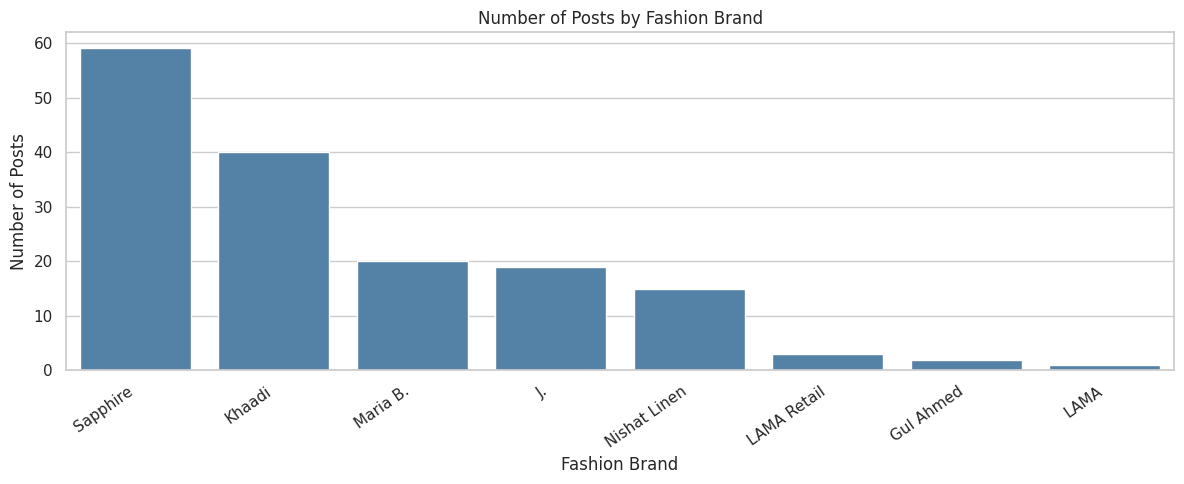

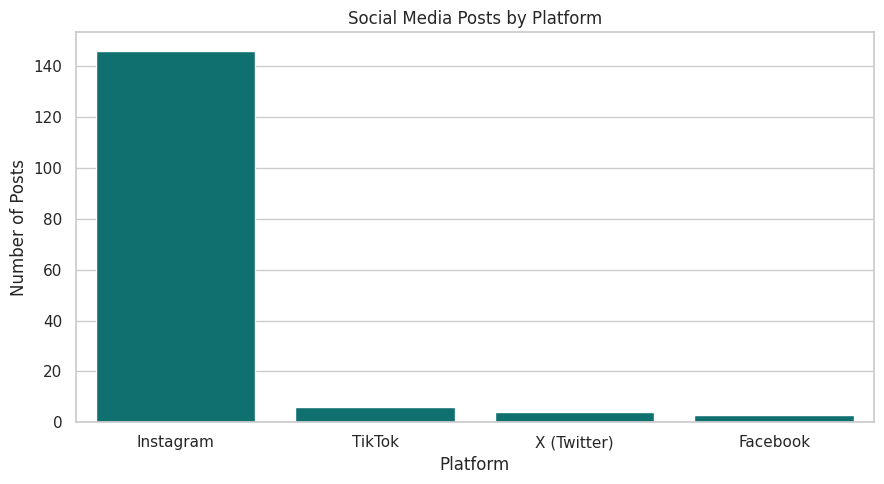

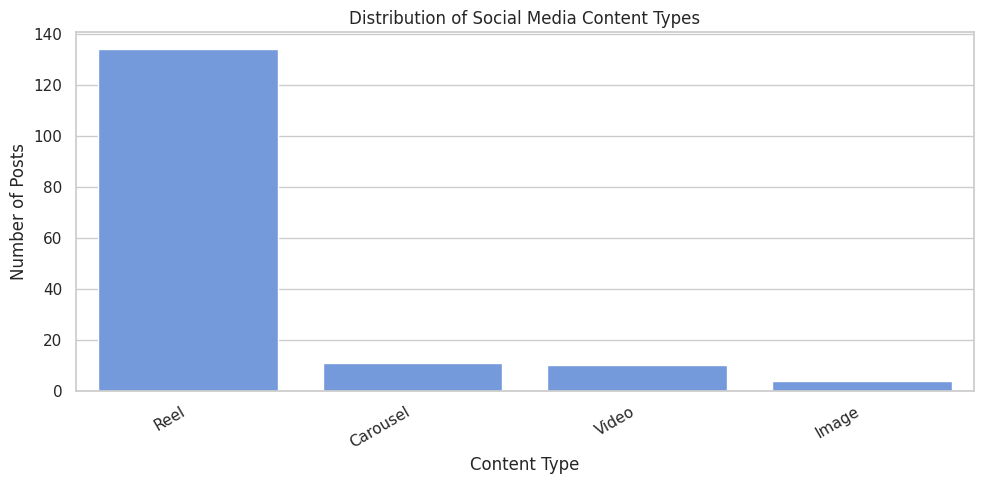

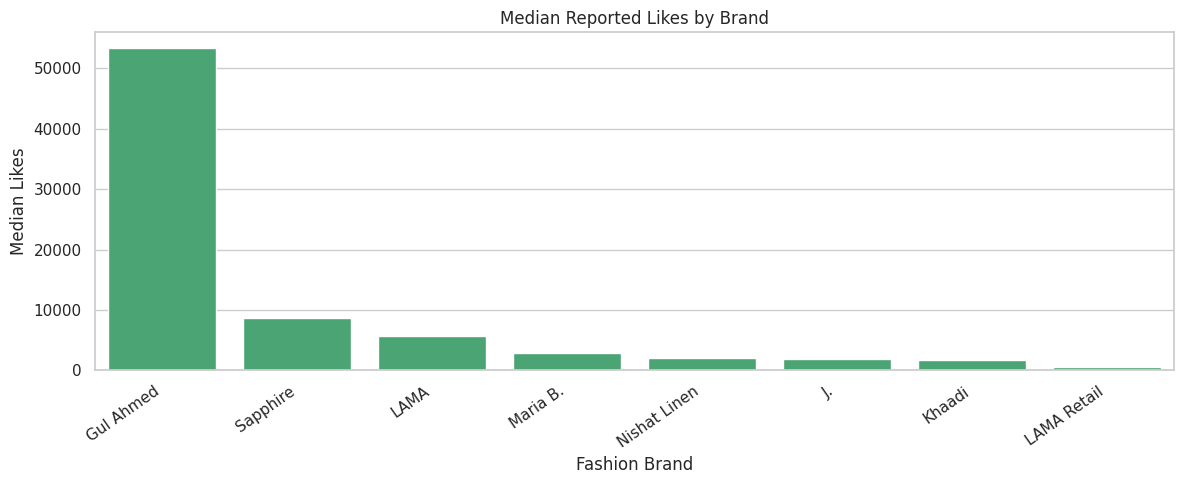

===== BRAND PERFORMANCE SUMMARY =====


,brand,total_posts,total_comments_reported,median_likes,posts_with_likes
0,Gul Ahmed,2,100.0,53250.0,2
1,J.,19,35495.0,1867.0,17
2,Khaadi,40,2182.0,1740.0,39
3,LAMA,1,44.0,5686.0,1
4,LAMA Retail,3,76.0,558.0,3
5,Maria B.,20,4864.0,2959.0,18
6,Nishat Linen,15,4821.0,2131.0,15
7,Sapphire,59,25047.0,8618.5,58



EDA Step 6 completed successfully!


In [6]:

# STEP 6: Exploratory Data Analysis (EDA)

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")

# ===== 1. BRAND-WISE POSTS =====

brand_counts = posts_clean["brand"].value_counts()

plt.figure(figsize=(12, 5))
sns.barplot(
    x=brand_counts.index,
    y=brand_counts.values,
    color="steelblue"
)

plt.title("Number of Posts by Fashion Brand")
plt.xlabel("Fashion Brand")
plt.ylabel("Number of Posts")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


# ===== 2. PLATFORM DISTRIBUTION =====

platform_counts = posts_clean["platform"].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(
    x=platform_counts.index,
    y=platform_counts.values,
    color="teal"
)

plt.title("Social Media Posts by Platform")
plt.xlabel("Platform")
plt.ylabel("Number of Posts")
plt.tight_layout()
plt.show()


# ===== 3. CONTENT TYPE DISTRIBUTION =====

content_counts = posts_clean["post_type"].value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(
    x=content_counts.index,
    y=content_counts.values,
    color="cornflowerblue"
)

plt.title("Distribution of Social Media Content Types")
plt.xlabel("Content Type")
plt.ylabel("Number of Posts")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# ===== 4. MEDIAN LIKES BY BRAND =====

likes_data = posts_clean.dropna(
    subset=["likes"]
)

median_likes = (
    likes_data.groupby("brand")["likes"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 5))
sns.barplot(
    x=median_likes.index,
    y=median_likes.values,
    color="mediumseagreen"
)

plt.title("Median Reported Likes by Brand")
plt.xlabel("Fashion Brand")
plt.ylabel("Median Likes")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


# ===== 5. SUMMARY TABLE =====

brand_summary = (
    posts_clean.groupby("brand")
    .agg(
        total_posts=("post_id", "count"),
        total_comments_reported=("comments_count", "sum"),
        median_likes=("likes", "median"),
        posts_with_likes=("likes", "count")
    )
    .reset_index()
)

print("===== BRAND PERFORMANCE SUMMARY =====")
display(brand_summary)

print("\nEDA Step 6 completed successfully!")


Available Columns:
['comment_id', 'post_id', 'platform', 'comment_text', 'manual_sentiment', 'language', 'topic', 'source', 'is_reply', 'language_standardized', 'normalized_text', 'data_quality_flags', 'needs_review', 'intent_rule_label', 'sentiment_model_prediction', 'sentiment_prediction_confidence', 'label_status', 'recommended_manual_review', 'clean_text', 'comment_length', 'word_count', 'contains_question', 'contains_urdu_script', 'brand', 'post_platform', 'post_type']


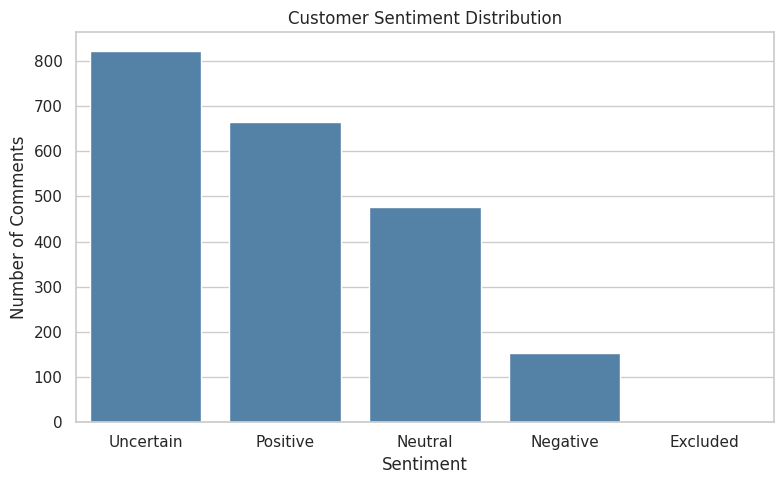

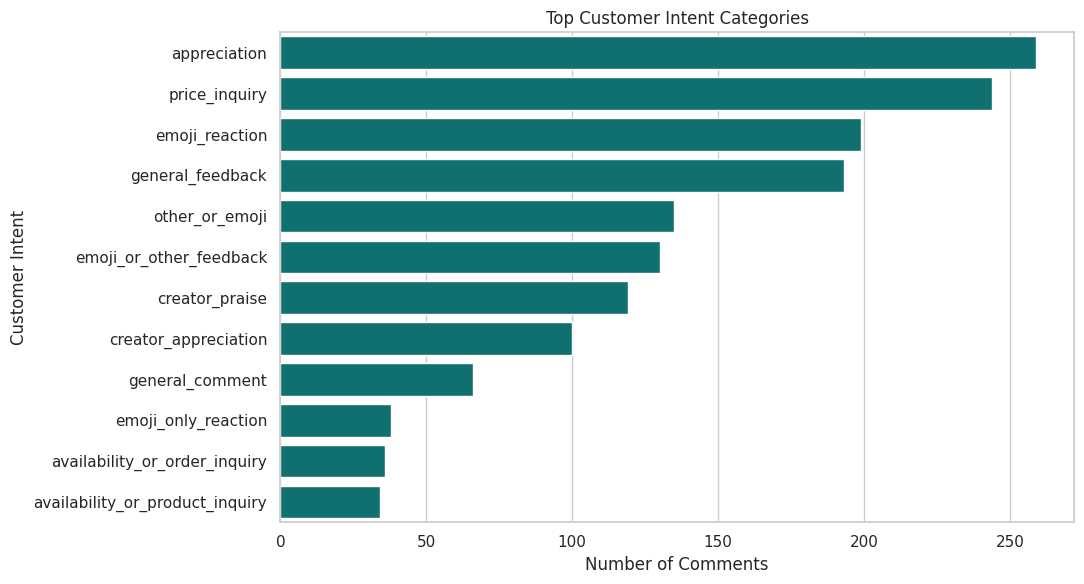

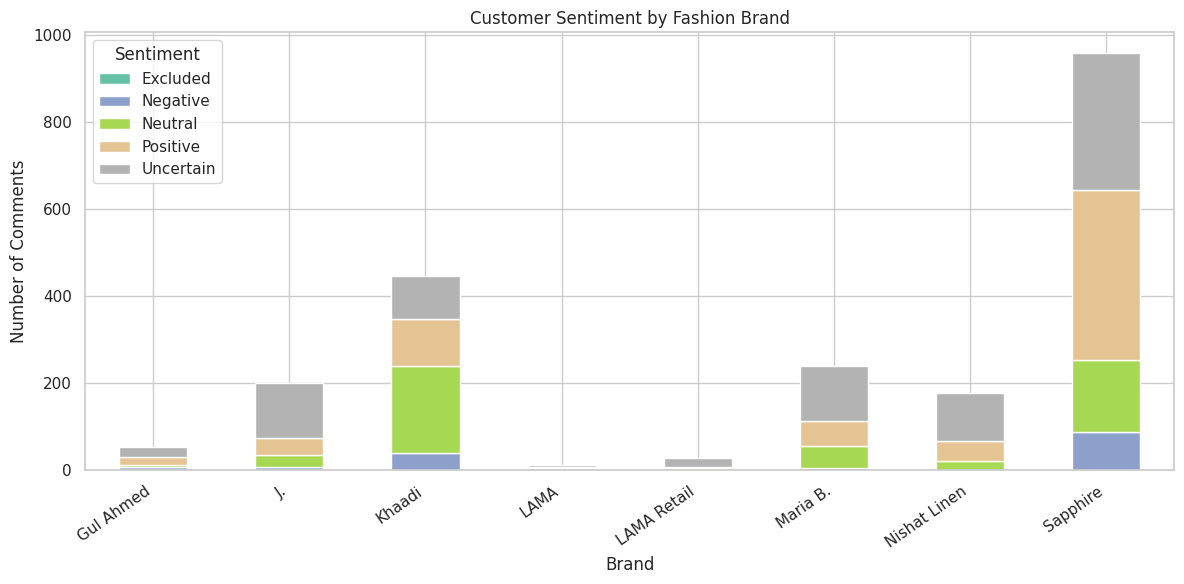

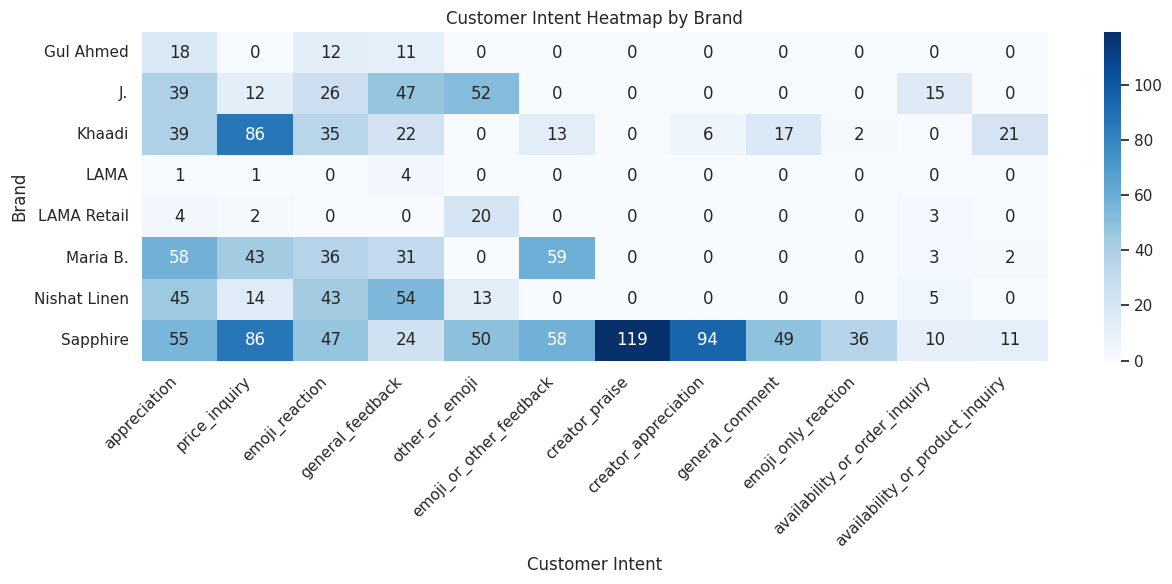

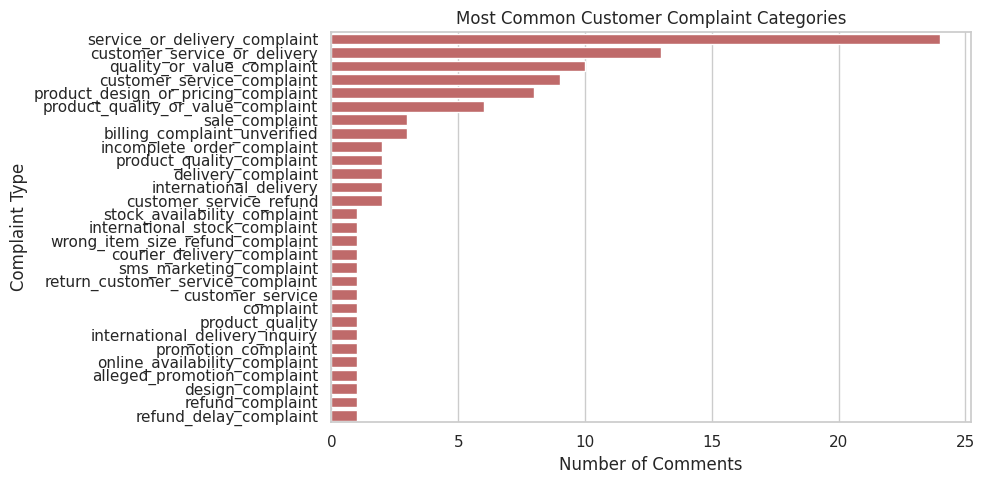

Total Comments: 2118

Sentiment Distribution:


,Comments
manual_sentiment,
Uncertain,822
Positive,664
Neutral,477
Negative,154
Excluded,1



Customer Intent Distribution:


,Comments
topic,
appreciation,259
price_inquiry,244
emoji_reaction,199
general_feedback,193
other_or_emoji,135
emoji_or_other_feedback,130
creator_praise,119
creator_appreciation,100
general_comment,66



Step 7 completed successfully!


In [7]:

# STEP 7: Customer Sentiment & Intent Analysis

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# ===== 1. CHECK AVAILABLE LABEL COLUMNS =====

print("Available Columns:")
print(comments_clean.columns.tolist())

# Existing labels are provisional.
# We will train and evaluate our own ML model later.

sentiment_col = "manual_sentiment"
intent_col = "topic"

if sentiment_col not in comments_clean.columns:
    raise ValueError("manual_sentiment column not found.")

if intent_col not in comments_clean.columns:
    raise ValueError("topic column not found.")

# ===== 2. SENTIMENT DISTRIBUTION =====

sentiment_counts = (
    comments_clean[sentiment_col]
    .fillna("Uncertain")
    .value_counts()
)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values,
    color="steelblue"
)

plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Comments")
plt.tight_layout()
plt.show()


# ===== 3. CUSTOMER INTENT DISTRIBUTION =====

intent_counts = (
    comments_clean[intent_col]
    .fillna("Other")
    .value_counts()
    .head(12)
)

plt.figure(figsize=(11, 6))
sns.barplot(
    x=intent_counts.values,
    y=intent_counts.index,
    color="teal"
)

plt.title("Top Customer Intent Categories")
plt.xlabel("Number of Comments")
plt.ylabel("Customer Intent")
plt.tight_layout()
plt.show()


# ===== 4. BRAND-WISE SENTIMENT =====

brand_sentiment = pd.crosstab(
    comments_clean["brand"],
    comments_clean[sentiment_col].fillna("Uncertain")
)

brand_sentiment.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="Set2"
)

plt.title("Customer Sentiment by Fashion Brand")
plt.xlabel("Brand")
plt.ylabel("Number of Comments")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()


# ===== 5. BRAND-WISE CUSTOMER INTENT =====

brand_intent = pd.crosstab(
    comments_clean["brand"],
    comments_clean[intent_col].fillna("Other")
)

top_intents = intent_counts.index.tolist()

brand_intent = brand_intent.reindex(
    columns=top_intents,
    fill_value=0
)

plt.figure(figsize=(13, 6))

sns.heatmap(
    brand_intent,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Customer Intent Heatmap by Brand")
plt.xlabel("Customer Intent")
plt.ylabel("Brand")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# ===== 6. MOST COMMON COMPLAINT TYPES =====

complaint_keywords = [
    "complaint", "quality", "delivery",
    "refund", "service", "damaged",
    "wrong", "return"
]

complaints = comments_clean[
    comments_clean[intent_col]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.contains("|".join(complaint_keywords))
]

complaint_counts = (
    complaints[intent_col]
    .value_counts()
)

if not complaint_counts.empty:
    plt.figure(figsize=(10, 5))

    sns.barplot(
        x=complaint_counts.values,
        y=complaint_counts.index,
        color="indianred"
    )

    plt.title("Most Common Customer Complaint Categories")
    plt.xlabel("Number of Comments")
    plt.ylabel("Complaint Type")
    plt.tight_layout()
    plt.show()
else:
    print("No complaint categories matched the keywords.")

# ===== 7. SUMMARY =====

print("Total Comments:", len(comments_clean))

print("\nSentiment Distribution:")
display(sentiment_counts.to_frame("Comments"))

print("\nCustomer Intent Distribution:")
display(intent_counts.to_frame("Comments"))

print("\nStep 7 completed successfully!")


In [8]:

# STEP 8.1: Upload labelled training dataset

from google.colab import files
import pandas as pd

uploaded = files.upload()

# Upload: annotation_400_reviewed_for_training.csv


Saving annotation_400_reviewed_for_training.csv to annotation_400_reviewed_for_training.csv


In [9]:

# STEP 8.2: Prepare data for sentiment classification

import numpy as np
from sklearn.model_selection import GroupShuffleSplit

# Load labelled CSV
df = pd.read_csv("annotation_400_reviewed_for_training.csv")

print("Available columns:")
print(df.columns.tolist())

required = [
    "comment_id",
    "post_id",
    "comment_text",
    "human_sentiment"
]

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# Keep only rows with usable sentiment labels
valid_labels = ["Positive", "Negative", "Neutral"]

df["human_sentiment"] = (
    df["human_sentiment"].astype("string").str.strip().str.title()
)

train_data = df[
    df["human_sentiment"].isin(valid_labels)
    & df["comment_text"].notna()
    & df["post_id"].notna()
].copy()

train_data["text"] = (
    train_data["comment_text"]
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

train_data = train_data[
    train_data["text"].str.len() > 0
]

train_data = train_data.drop_duplicates(
    subset=["comment_id"]
)

# Split by POST, not random comments
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        train_data["text"],
        train_data["human_sentiment"],
        groups=train_data["post_id"]
    )
)

train_df = train_data.iloc[train_idx].copy()
test_df = train_data.iloc[test_idx].copy()

X_train = train_df["text"]
X_test = test_df["text"]

y_train = train_df["human_sentiment"]
y_test = test_df["human_sentiment"]

print("\n===== TRAINING DATA =====")
print("Total labelled comments:", len(train_data))
print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

print("\nPost leakage check:")
print(
    "Overlapping posts:",
    len(set(train_df["post_id"]) & set(test_df["post_id"]))
)

display(train_df[["comment_text", "human_sentiment"]].head())


Available columns:
['comment_id', 'post_id', 'language_standardized', 'comment_text', 'existing_sentiment', 'model_suggestion', 'intent_suggestion', 'human_sentiment', 'human_intent', 'annotator_notes', 'original_human_sentiment', 'original_human_intent', 'original_annotator_notes', 'review_status', 'label_source', 'human_verified']

===== TRAINING DATA =====
Total labelled comments: 383
Training samples: 290
Testing samples: 93

Training class distribution:
human_sentiment
Neutral     127
Positive     88
Negative     75
Name: count, dtype: Int64

Testing class distribution:
human_sentiment
Neutral     40
Positive    34
Negative    19
Name: count, dtype: Int64

Post leakage check:
Overlapping posts: 0


,comment_text,human_sentiment
0,White skirt shirt available ?,Neutral
2,Khadi ka size change ho jaye ga ?,Neutral
3,Ye articles unstitched me Hy??,Neutral
4,Gents ka kapre hote he nhi hai,Negative
5,Laiba khan g aik dil h kitni martaba jity gi🥺🥺,Positive


In [10]:

# STEP 9.1: Sentiment Model Training

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report
)
import pandas as pd

# Model 1: Logistic Regression
lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 5),
        min_df=1,
        max_features=30000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Model 2: Linear SVM
svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 5),
        min_df=1,
        max_features=30000,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

models = {
    "Logistic Regression": lr_model,
    "Linear SVM": svm_model
}

results = []

for name, model in models.items():

    print(f"\n===== Training {name} =====")

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(
        y_test, predictions,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": round(accuracy, 4),
        "Macro_F1": round(macro_f1, 4)
    })

    print(classification_report(
        y_test, predictions,
        zero_division=0
    ))

# Compare models
results_df = pd.DataFrame(results)
display(results_df.sort_values("Macro_F1", ascending=False))

print("\nStep 9 completed successfully!")



===== Training Logistic Regression =====
              precision    recall  f1-score   support

    Negative       0.45      0.74      0.56        19
     Neutral       0.78      0.70      0.74        40
    Positive       0.81      0.62      0.70        34

    accuracy                           0.68        93
   macro avg       0.68      0.68      0.67        93
weighted avg       0.72      0.68      0.69        93


===== Training Linear SVM =====
              precision    recall  f1-score   support

    Negative       0.45      0.68      0.54        19
     Neutral       0.64      0.72      0.68        40
    Positive       0.84      0.47      0.60        34

    accuracy                           0.62        93
   macro avg       0.64      0.63      0.61        93
weighted avg       0.68      0.62      0.62        93



,Model,Accuracy,Macro_F1
0,Logistic Regression,0.6774,0.6656
1,Linear SVM,0.6237,0.6093



Step 9 completed successfully!


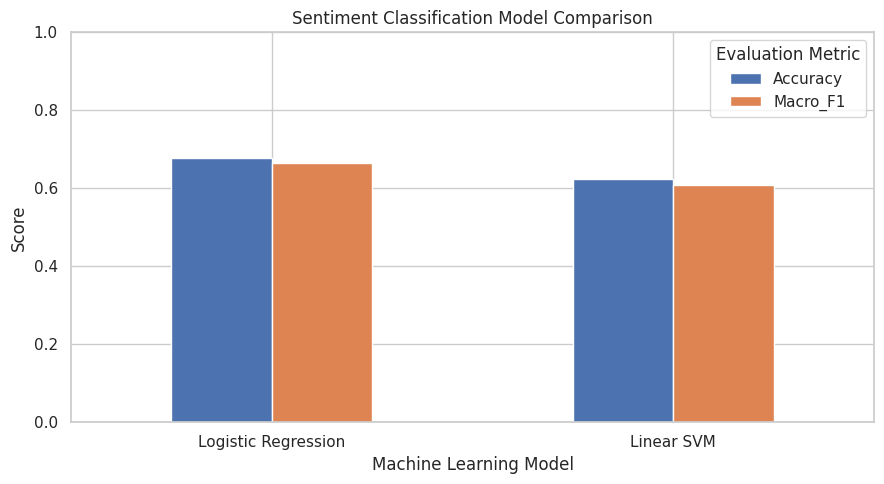

Best Sentiment Model: Logistic Regression


In [11]:

# STEP 9.2: Compare Model Performance

import matplotlib.pyplot as plt

comparison = results_df.set_index("Model")[
    ["Accuracy", "Macro_F1"]
]

ax = comparison.plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Sentiment Classification Model Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.legend(title="Evaluation Metric")
plt.tight_layout()
plt.show()

best_name = results_df.sort_values(
    "Macro_F1", ascending=False
).iloc[0]["Model"]

best_sentiment_model = models[best_name]

print("Best Sentiment Model:", best_name)


In [12]:

# STEP 10.1: Prepare Customer Intent Dataset

from sklearn.model_selection import GroupShuffleSplit
import pandas as pd

# Same reviewed annotation dataset from Step 8
intent_data = df.copy()

valid_intents = [
    "Appreciation",
    "Price_inquiry",
    "Availability_inquiry",
    "Purchase_interest",
    "Service_complaint",
    "Quality_feedback",
    "Other"
]

# Standardize labels
intent_data["human_intent"] = (
    intent_data["human_intent"]
    .astype("string")
    .str.strip()
)

# Keep valid labelled comments
intent_data = intent_data[
    intent_data["human_intent"].isin(valid_intents)
    & intent_data["comment_text"].notna()
    & intent_data["post_id"].notna()
].copy()

intent_data["text"] = (
    intent_data["comment_text"]
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

intent_data = intent_data[
    intent_data["text"].str.len() > 0
].drop_duplicates(subset=["comment_id"])

# Keep the same held-out post groups used for sentiment.
# This prevents selecting models on unrelated test splits.
test_post_ids = set(test_df["post_id"])

intent_train_df = intent_data[
    ~intent_data["post_id"].isin(test_post_ids)
].copy()

intent_test_df = intent_data[
    intent_data["post_id"].isin(test_post_ids)
].copy()

# Some intent-labelled posts may not have sentiment labels.
# Keep them in training, never in the held-out sentiment test posts.
if intent_train_df.empty or intent_test_df.empty:
    raise ValueError(
        "Intent train/test split is empty. Check annotation labels."
    )

X_train_intent = intent_train_df["text"]
X_test_intent = intent_test_df["text"]

y_train_intent = intent_train_df["human_intent"]
y_test_intent = intent_test_df["human_intent"]

print("===== INTENT DATASET =====")
print("Total labelled:", len(intent_data))
print("Train samples:", len(intent_train_df))
print("Test samples:", len(intent_test_df))

print("\nTraining labels:")
print(y_train_intent.value_counts())

print("\nTesting labels:")
print(y_test_intent.value_counts())

print("\nPost overlap:",
      len(set(intent_train_df["post_id"])
          & set(intent_test_df["post_id"])))


===== INTENT DATASET =====
Total labelled: 386
Train samples: 293
Test samples: 93

Training labels:
human_intent
Other                   83
Appreciation            79
Availability_inquiry    71
Service_complaint       29
Price_inquiry           12
Purchase_interest       11
Quality_feedback         8
Name: count, dtype: Int64

Testing labels:
human_intent
Appreciation            30
Other                   22
Availability_inquiry    17
Price_inquiry            8
Service_complaint        8
Quality_feedback         5
Purchase_interest        3
Name: count, dtype: Int64

Post overlap: 0


In [13]:

# STEP 10.2: Train Customer Intent Models

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report
)

intent_models = {
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            analyzer="char",
            ngram_range=(2, 5),
            max_features=30000,
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(
            analyzer="char",
            ngram_range=(2, 5),
            max_features=30000,
            sublinear_tf=True
        )),
        ("classifier", LinearSVC(
            class_weight="balanced",
            random_state=42
        ))
    ])
}

intent_results = []

for name, model in intent_models.items():
    print(f"\n===== {name} =====")

    model.fit(X_train_intent, y_train_intent)

    y_pred = model.predict(X_test_intent)

    accuracy = accuracy_score(y_test_intent, y_pred)
    macro_f1 = f1_score(
        y_test_intent, y_pred,
        average="macro",
        labels=valid_intents,
        zero_division=0
    )

    intent_results.append({
        "Model": name,
        "Accuracy": round(accuracy, 4),
        "Macro_F1": round(macro_f1, 4)
    })

    print(classification_report(
        y_test_intent,
        y_pred,
        labels=valid_intents,
        zero_division=0
    ))

intent_results_df = pd.DataFrame(intent_results)

print("\n===== MODEL COMPARISON =====")
display(intent_results_df.sort_values(
    "Macro_F1", ascending=False
))



===== Logistic Regression =====
                      precision    recall  f1-score   support

        Appreciation       0.82      0.60      0.69        30
       Price_inquiry       0.80      0.50      0.62         8
Availability_inquiry       0.74      0.82      0.78        17
   Purchase_interest       0.00      0.00      0.00         3
   Service_complaint       0.38      0.62      0.48         8
    Quality_feedback       0.00      0.00      0.00         5
               Other       0.58      0.86      0.69        22

            accuracy                           0.65        93
           macro avg       0.47      0.49      0.46        93
        weighted avg       0.64      0.65      0.62        93


===== Linear SVM =====
                      precision    recall  f1-score   support

        Appreciation       0.86      0.60      0.71        30
       Price_inquiry       0.75      0.38      0.50         8
Availability_inquiry       0.64      0.82      0.72        17
   Purcha

,Model,Accuracy,Macro_F1
1,Linear SVM,0.6344,0.4938
0,Logistic Regression,0.6452,0.4647


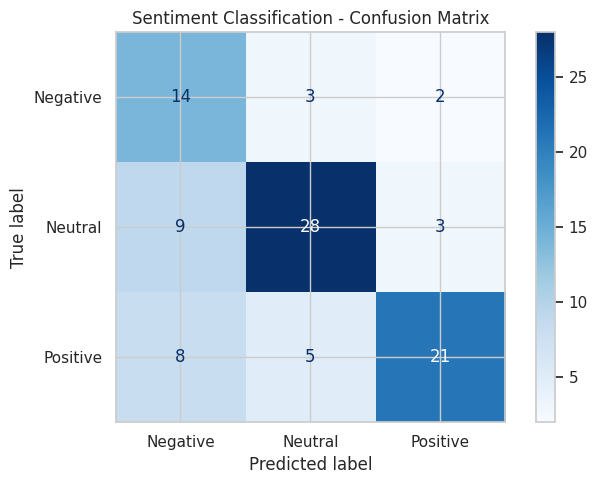

===== SENTIMENT CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

    Negative       0.45      0.74      0.56        19
     Neutral       0.78      0.70      0.74        40
    Positive       0.81      0.62      0.70        34

    accuracy                           0.68        93
   macro avg       0.68      0.68      0.67        93
weighted avg       0.72      0.68      0.69        93



In [14]:

# STEP 11.1: Sentiment Model Evaluation

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
import matplotlib.pyplot as plt
import pandas as pd

# Predict using best sentiment model
sentiment_pred = best_sentiment_model.predict(X_test)

sentiment_labels = ["Negative", "Neutral", "Positive"]

cm = confusion_matrix(
    y_test,
    sentiment_pred,
    labels=sentiment_labels
)

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=sentiment_labels
).plot(ax=ax, cmap="Blues", values_format="d")

plt.title("Sentiment Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

print("===== SENTIMENT CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    sentiment_pred,
    labels=sentiment_labels,
    zero_division=0
))


Best Intent Model Selected: Linear SVM


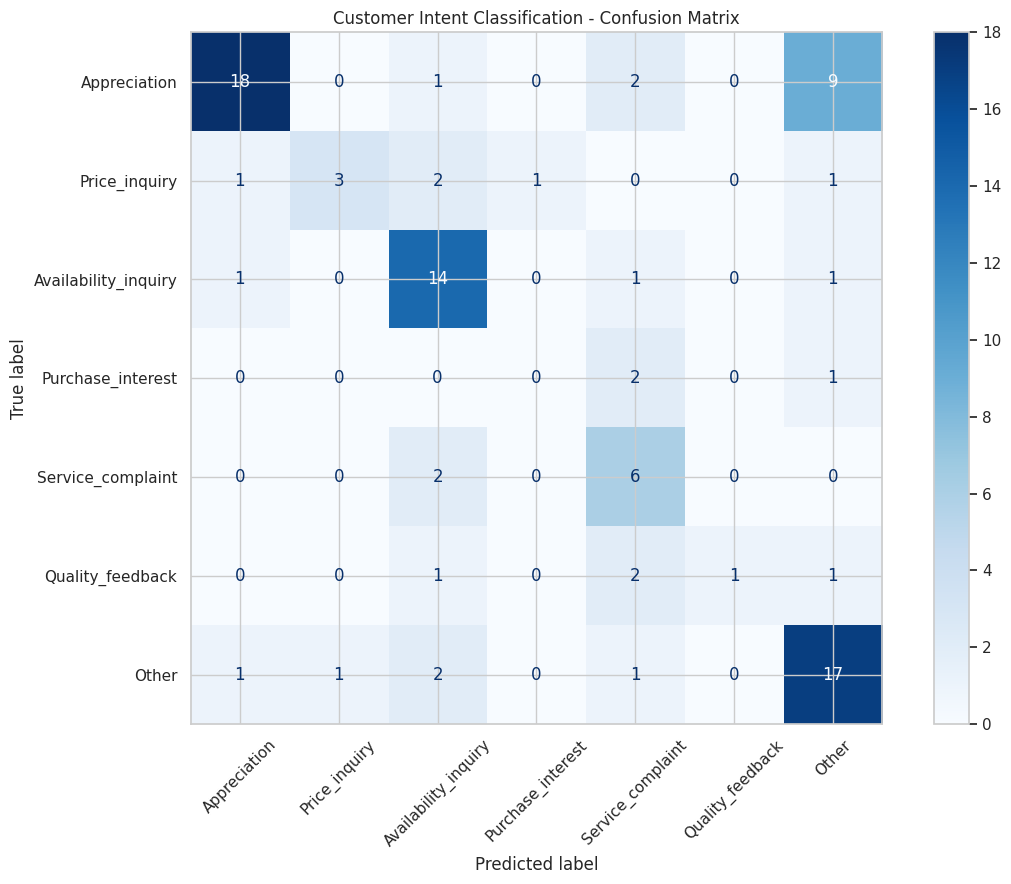

===== INTENT CLASSIFICATION REPORT =====
                      precision    recall  f1-score   support

        Appreciation       0.86      0.60      0.71        30
       Price_inquiry       0.75      0.38      0.50         8
Availability_inquiry       0.64      0.82      0.72        17
   Purchase_interest       0.00      0.00      0.00         3
   Service_complaint       0.43      0.75      0.55         8
    Quality_feedback       1.00      0.20      0.33         5
               Other       0.57      0.77      0.65        22

            accuracy                           0.63        93
           macro avg       0.61      0.50      0.49        93
        weighted avg       0.68      0.63      0.62        93



In [16]:
# STEP 11.2: Intent Model Evaluation

# Identify and extract the best performing intent model based on Macro_F1
best_intent_name = intent_results_df.sort_values(
    "Macro_F1", ascending=False
).iloc[0]["Model"]

best_intent_model = intent_models[best_intent_name]
print("Best Intent Model Selected:", best_intent_name)

intent_pred = best_intent_model.predict(X_test_intent)

cm_intent = confusion_matrix(
    y_test_intent,
    intent_pred,
    labels=valid_intents
)

fig, ax = plt.subplots(figsize=(12, 9))

ConfusionMatrixDisplay(
    confusion_matrix=cm_intent,
    display_labels=valid_intents
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("Customer Intent Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

print("===== INTENT CLASSIFICATION REPORT =====")
print(classification_report(
    y_test_intent,
    intent_pred,
    labels=valid_intents,
    zero_division=0
))

In [17]:

# STEP 11.3: Misclassified Comments Analysis

# Sentiment errors
sentiment_errors = test_df[
    ["comment_id", "post_id", "text", "human_sentiment"]
].copy()

sentiment_errors["predicted_sentiment"] = sentiment_pred

sentiment_errors = sentiment_errors[
    sentiment_errors["human_sentiment"]
    != sentiment_errors["predicted_sentiment"]
]

print("===== SENTIMENT ERRORS =====")
print("Total errors:", len(sentiment_errors))
display(sentiment_errors.head(15))


# Intent errors
intent_errors = intent_test_df[
    ["comment_id", "post_id", "text", "human_intent"]
].copy()

intent_errors["predicted_intent"] = intent_pred

intent_errors = intent_errors[
    intent_errors["human_intent"]
    != intent_errors["predicted_intent"]
]

print("\n===== INTENT ERRORS =====")
print("Total errors:", len(intent_errors))
display(intent_errors.head(15))


===== SENTIMENT ERRORS =====
Total errors: 30


,comment_id,post_id,text,human_sentiment,predicted_sentiment
13,JJ_IG_016_C001,JJ_IG_016,Mardon me shalwar takhno se uper rekhty hai☝️,Neutral,Negative
14,JJ_IG_016_C006,JJ_IG_016,Kya me ye india me bhi maga sakta hu kya bhai,Neutral,Negative
43,JJ_IG_016_C011,JJ_IG_016,Ap ki ab promotions bohat fit hoti.. baki sb a...,Positive,Neutral
51,SP_IG_050_C006,SP_IG_050,Kahan Hain yia dress wibeside per Tu Nahi dekahy,Neutral,Negative
53,SP_IG_016_C007,SP_IG_016,Zamil ko pta hai yeh sab.....❓,Neutral,Negative
93,SP_IG_051_C003,SP_IG_051,My father and me still wear loose shalwaar kam...,Neutral,Negative
132,SP_IG_051_C007,SP_IG_051,Eid par sapphire AUR HUZTORY ka Collab bhi ab ...,Neutral,Negative
173,JJ_IG_016_C007,JJ_IG_016,Pakistan? Heritage? Gora complex took everythi...,Negative,Positive
206,NL_IG_003_C009,NL_IG_003,Visited BP such a beautiful city. Thanks to sh...,Positive,Negative
210,KH_IG_012_C006,KH_IG_012,That’s block printed technique,Neutral,Negative



===== INTENT ERRORS =====
Total errors: 34


,comment_id,post_id,text,human_intent,predicted_intent
14,JJ_IG_016_C006,JJ_IG_016,Kya me ye india me bhi maga sakta hu kya bhai,Availability_inquiry,Service_complaint
51,SP_IG_050_C006,SP_IG_050,Kahan Hain yia dress wibeside per Tu Nahi dekahy,Availability_inquiry,Other
95,KH_FB_003_C013,KH_FB_003,Sab ke sab aik jaise aur dull !,Quality_feedback,Other
105,KH_FB_003_C007,KH_FB_003,Kis Kya Paris ha,Price_inquiry,Other
106,SP_IG_002_C020,SP_IG_002,Sasi g 🔥😂,Other,Appreciation
109,KH_IG_012_C007,KH_IG_012,Aj se 10 sal pehle wale design phir se,Quality_feedback,Service_complaint
110,SP_IG_044_C011,SP_IG_044,@mehakksohaiill slayyyy,Appreciation,Other
130,GA_TT_001_C012,GA_TT_001,💚اے ون,Appreciation,Other
132,SP_IG_051_C007,SP_IG_051,Eid par sapphire AUR HUZTORY ka Collab bhi ab ...,Other,Service_complaint
159,SP_IG_002_C024,SP_IG_002,گل رعنا 🌸,Appreciation,Other


In [18]:

# STEP 11.4: Save misclassified comments

sentiment_errors.to_csv(
    "sentiment_errors.csv",
    index=False,
    encoding="utf-8-sig"
)

intent_errors.to_csv(
    "intent_errors.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Error analysis CSV files saved successfully!")


Error analysis CSV files saved successfully!


In [19]:

# STEP 12.1: Predict sentiment and intent for all comments

import pandas as pd
from sklearn.base import clone

# Retrain selected models on all available labelled data
# Only after completing the evaluation in Step 11

final_sentiment_model = clone(best_sentiment_model)
final_sentiment_model.fit(
    train_data["text"],
    train_data["human_sentiment"]
)

final_intent_model = clone(best_intent_model)
final_intent_model.fit(
    intent_data["text"],
    intent_data["human_intent"]
)

# Copy cleaned comments dataset
final_comments = comments_clean.copy()

# Generate predictions
final_comments["predicted_sentiment"] = (
    final_sentiment_model.predict(final_comments["clean_text"])
)

final_comments["predicted_intent"] = (
    final_intent_model.predict(final_comments["clean_text"])
)

print("===== PREDICTION COMPLETED =====")
print("Total comments processed:", len(final_comments))

display(
    final_comments[
        ["comment_id", "brand", "clean_text",
         "predicted_sentiment", "predicted_intent"]
    ].head(15)
)


===== PREDICTION COMPLETED =====
Total comments processed: 2118


,comment_id,brand,clean_text,predicted_sentiment,predicted_intent
0,KH_IG_001_C001,Khaadi,😍😍,Positive,Appreciation
1,KH_IG_001_C002,Khaadi,Beautiful!!!,Positive,Appreciation
2,KH_IG_001_C003,Khaadi,Nice,Positive,Appreciation
3,KH_IG_001_C004,Khaadi,Worst experience,Negative,Service_complaint
4,KH_IG_001_C005,Khaadi,They sent me torn dupatta,Negative,Other
5,KH_IG_001_C006,Khaadi,I need to complain about a dress,Negative,Other
6,KH_IG_001_C007,Khaadi,🔥❤️,Positive,Appreciation
7,KH_IG_001_C008,Khaadi,Pls send your complaint number,Neutral,Availability_inquiry
8,KH_IG_001_C009,Khaadi,That rich crimson with the delicate white thre...,Positive,Appreciation
9,KH_IG_001_C010,Khaadi,Nice print,Positive,Appreciation


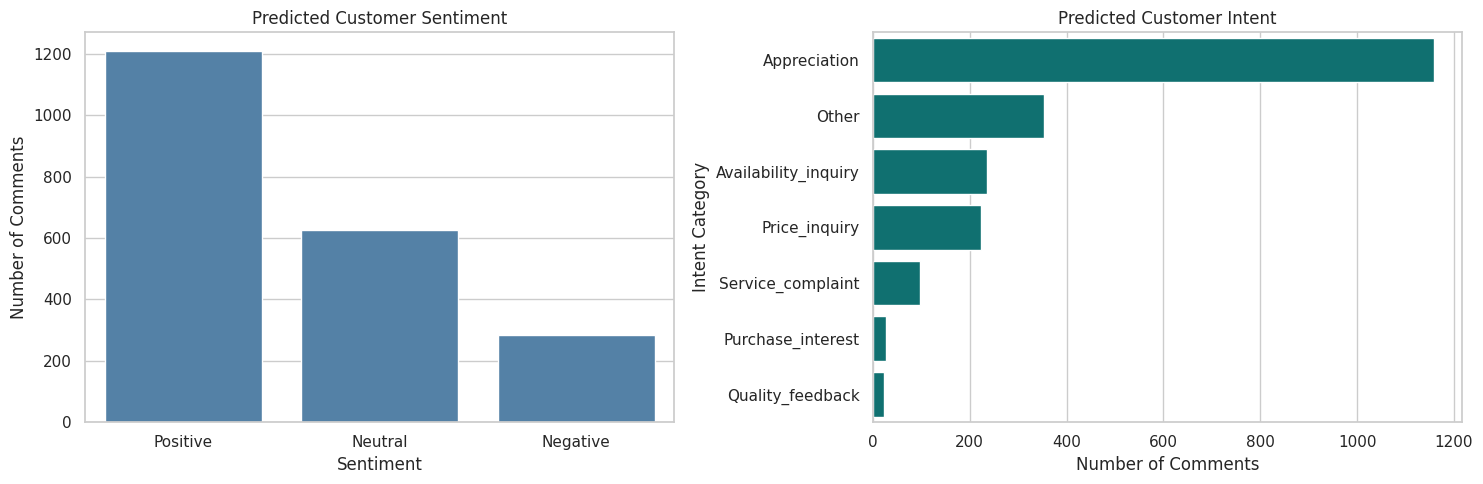

In [20]:

# STEP 12.2: Visualize ML predictions

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(
    data=final_comments,
    x="predicted_sentiment",
    order=final_comments["predicted_sentiment"].value_counts().index,
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Predicted Customer Sentiment")
axes[0].set_xlabel("Sentiment")
axes[0].set_ylabel("Number of Comments")

intent_order = (
    final_comments["predicted_intent"]
    .value_counts()
    .index
)

sns.countplot(
    data=final_comments,
    y="predicted_intent",
    order=intent_order,
    ax=axes[1],
    color="teal"
)

axes[1].set_title("Predicted Customer Intent")
axes[1].set_xlabel("Number of Comments")
axes[1].set_ylabel("Intent Category")

plt.tight_layout()
plt.show()


In [21]:

# STEP 12.3: Export predicted dataset

from google.colab import files

output_file = "final_classified_comments.csv"

final_comments.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

print("Dataset exported successfully!")
print("Total rows:", len(final_comments))
print("Filename:", output_file)

files.download(output_file)


Dataset exported successfully!
Total rows: 2118
Filename: final_classified_comments.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

===== BRAND-WISE SENTIMENT (%) =====


predicted_sentiment,Negative,Neutral,Positive
brand,,,
Gul Ahmed,12.96,25.93,61.11
J.,15.00,31.00,54.00
Khaadi,10.96,48.55,40.49
LAMA,53.85,30.77,15.38
LAMA Retail,6.90,41.38,51.72
Maria B.,6.25,27.50,66.25
Nishat Linen,4.52,25.42,70.06
Sapphire,17.22,21.50,61.27


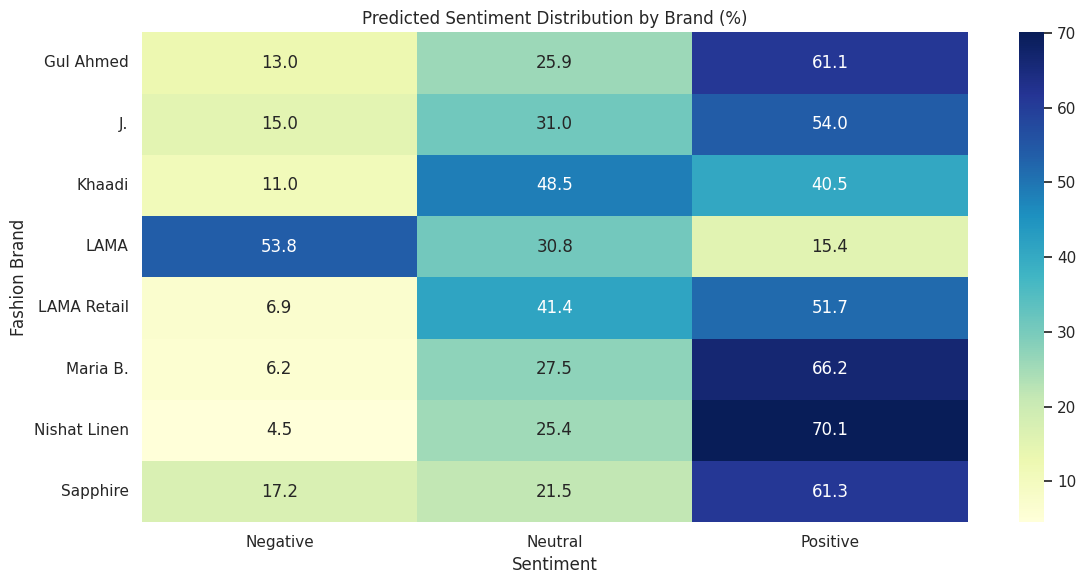


===== BRAND-WISE CUSTOMER INTENT (%) =====


predicted_intent,Appreciation,Availability_inquiry,Other,Price_inquiry,Purchase_interest,Quality_feedback,Service_complaint
brand,,,,,,,
Gul Ahmed,59.26,5.56,31.48,3.70,0.00,0.00,0.00
J.,52.00,11.50,23.00,8.50,2.00,1.00,2.00
Khaadi,40.49,21.48,10.29,19.02,2.68,2.46,3.58
LAMA,7.69,15.38,30.77,15.38,0.00,0.00,30.77
LAMA Retail,34.48,13.79,44.83,6.90,0.00,0.00,0.00
Maria B.,63.75,5.42,12.92,15.42,1.67,0.83,0.00
Nishat Linen,68.36,9.04,14.12,6.78,0.56,0.56,0.56
Sapphire,58.14,8.14,17.85,6.99,0.63,0.73,7.52


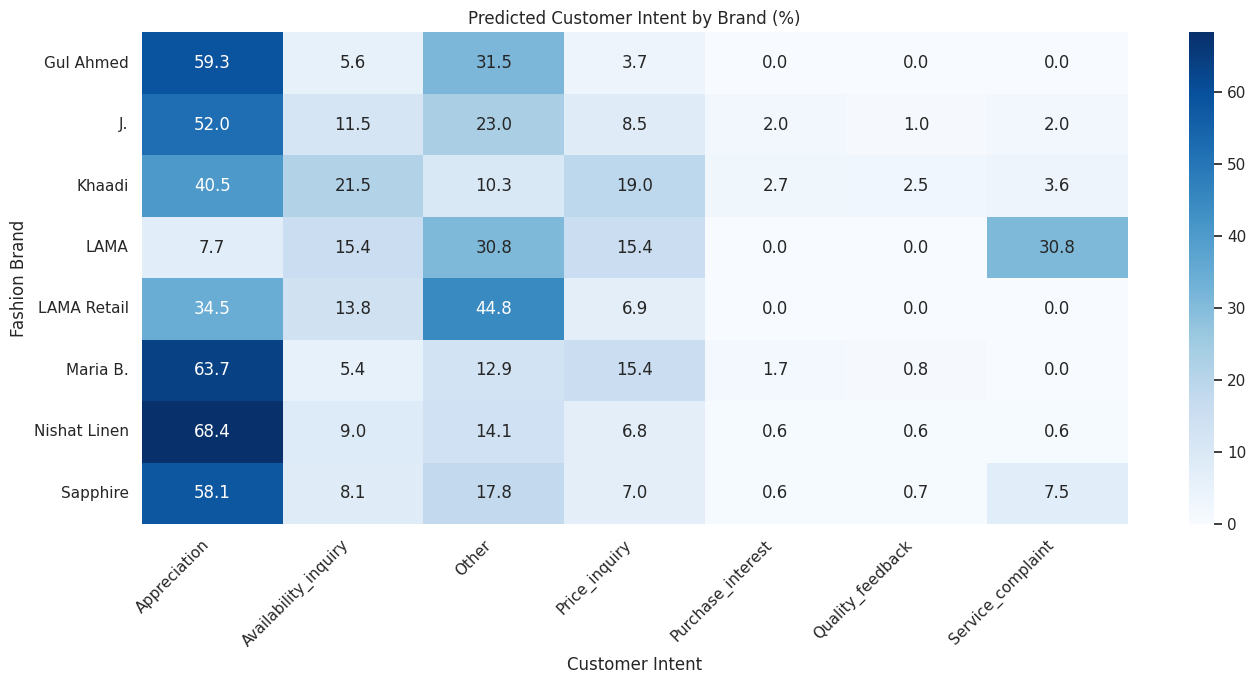

In [22]:

# STEP 13.1: Brand-Wise Customer Insights

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Brand-wise predicted sentiment
brand_sentiment = pd.crosstab(
    final_comments["brand"],
    final_comments["predicted_sentiment"],
    normalize="index"
) * 100

print("===== BRAND-WISE SENTIMENT (%) =====")
display(brand_sentiment.round(2))

plt.figure(figsize=(12, 6))

sns.heatmap(
    brand_sentiment,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Predicted Sentiment Distribution by Brand (%)")
plt.xlabel("Sentiment")
plt.ylabel("Fashion Brand")
plt.tight_layout()
plt.show()


# Brand-wise predicted customer intent
brand_intent = pd.crosstab(
    final_comments["brand"],
    final_comments["predicted_intent"],
    normalize="index"
) * 100

print("\n===== BRAND-WISE CUSTOMER INTENT (%) =====")
display(brand_intent.round(2))

plt.figure(figsize=(14, 7))

sns.heatmap(
    brand_intent,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Predicted Customer Intent by Brand (%)")
plt.xlabel("Customer Intent")
plt.ylabel("Fashion Brand")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [23]:

# STEP 13.2: Marketing Recommendation Engine

recommendations = []

recommendation_rules = {
    "Price_inquiry": (
        "Publish clear product prices in captions and product tags."
    ),
    "Availability_inquiry": (
        "Highlight stock availability, sizes, and restock updates."
    ),
    "Purchase_interest": (
        "Add clear purchase links and stronger shop-now CTAs."
    ),
    "Service_complaint": (
        "Prioritize customer support and resolve delivery or service issues."
    ),
    "Quality_feedback": (
        "Review product quality feedback and address recurring concerns."
    ),
    "Appreciation": (
        "Promote popular products and encourage customer testimonials."
    ),
    "Other": (
        "Review common customer questions to improve content relevance."
    )
}

for brand, group in final_comments.groupby("brand"):

    total_comments = len(group)

    intent_counts = group[
        "predicted_intent"
    ].value_counts()

    for intent, count in intent_counts.items():

        percentage = (count / total_comments) * 100

        recommendations.append({
            "Brand": brand,
            "Customer_Intent": intent,
            "Comments": count,
            "Percentage": round(percentage, 2),
            "Recommended_Action": recommendation_rules.get(
                intent,
                "Review comments manually for emerging patterns."
            )
        })

recommendations_df = pd.DataFrame(recommendations)

recommendations_df = recommendations_df.sort_values(
    ["Brand", "Percentage"],
    ascending=[True, False]
)

print("===== MARKETING RECOMMENDATIONS =====")
display(recommendations_df)


===== MARKETING RECOMMENDATIONS =====


,Brand,Customer_Intent,Comments,Percentage,Recommended_Action
0,Gul Ahmed,Appreciation,32,59.26,Promote popular products and encourage custome...
1,Gul Ahmed,Other,17,31.48,Review common customer questions to improve co...
2,Gul Ahmed,Availability_inquiry,3,5.56,"Highlight stock availability, sizes, and resto..."
3,Gul Ahmed,Price_inquiry,2,3.70,Publish clear product prices in captions and p...
4,J.,Appreciation,104,52.00,Promote popular products and encourage custome...
5,J.,Other,46,23.00,Review common customer questions to improve co...
6,J.,Availability_inquiry,23,11.50,"Highlight stock availability, sizes, and resto..."
7,J.,Price_inquiry,17,8.50,Publish clear product prices in captions and p...
8,J.,Purchase_interest,4,2.00,Add clear purchase links and stronger shop-now...
9,J.,Service_complaint,4,2.00,Prioritize customer support and resolve delive...


In [24]:

# STEP 13.3: Top Marketing Recommendation Per Brand

top_recommendations = (
    recommendations_df
    .sort_values("Percentage", ascending=False)
    .drop_duplicates(subset=["Brand"])
    .reset_index(drop=True)
)

print("===== TOP MARKETING OPPORTUNITIES =====")

display(
    top_recommendations[
        ["Brand", "Customer_Intent",
         "Percentage", "Recommended_Action"]
    ]
)


===== TOP MARKETING OPPORTUNITIES =====


,Brand,Customer_Intent,Percentage,Recommended_Action
0,Nishat Linen,Appreciation,68.36,Promote popular products and encourage custome...
1,Maria B.,Appreciation,63.75,Promote popular products and encourage custome...
2,Gul Ahmed,Appreciation,59.26,Promote popular products and encourage custome...
3,Sapphire,Appreciation,58.14,Promote popular products and encourage custome...
4,J.,Appreciation,52.00,Promote popular products and encourage custome...
5,LAMA Retail,Other,44.83,Review common customer questions to improve co...
6,Khaadi,Appreciation,40.49,Promote popular products and encourage custome...
7,LAMA,Other,30.77,Review common customer questions to improve co...


In [25]:

# STEP 13.4: Export Marketing Recommendations

from google.colab import files

recommendations_df.to_csv(
    "brand_marketing_recommendations.csv",
    index=False,
    encoding="utf-8-sig"
)

brand_sentiment.to_csv(
    "brand_sentiment_analysis.csv",
    encoding="utf-8-sig"
)

brand_intent.to_csv(
    "brand_intent_analysis.csv",
    encoding="utf-8-sig"
)

print("Marketing insights exported successfully!")

files.download("brand_marketing_recommendations.csv")
files.download("brand_sentiment_analysis.csv")
files.download("brand_intent_analysis.csv")


Marketing insights exported successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>